## SWYNEX BIOINFORMATICS PROJECT

### Task 3: Visualization and Interpretation
Dataset: GSE10072
Study: Lung Adenocarcinoma vs Non-Tumor Lung Tissue

Objective: To visualize gene expression data and interpret the observed patterns using appropriate statistical plots.

### Importing Required Libraries

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gzip
import csv

print("All required libraries imported successfully!")

All required libraries imported successfully!


### 3.1 Dataset Loading and Initial Inspection 

In [24]:
file_path = "../data/GSE10072_series_matrix.txt.gz"

# Locate the beginning of the expression table
with gzip.open(file_path, "rt") as file:
    for line_number, line in enumerate(file):
        if line.strip() == "!series_matrix_table_begin":
            skip_lines = line_number + 1
            break

# Load the expression data
df = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    skiprows=skip_lines,
    skipfooter=1,
    engine="python",
    index_col=0
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
import os

print("Current working directory:", os.getcwd())

Current working directory: D:\Bioinformatics\SWYNEX\notebook


In [4]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'SWYNEX_GSE10072_Complete_Analysis.ipynb', 'SWYNEX_Task2_Data_Cleaning.ipynb', 'SWYNEX_Task2_Submission.ipynb', 'SWYNEX_Task3_Visualization.ipynb']


In [5]:
df.head()

,GSM254625,GSM254626,GSM254627,GSM254628,GSM254629,GSM254630,GSM254631,GSM254632,GSM254633,GSM254634,...,GSM254722,GSM254723,GSM254724,GSM254725,GSM254726,GSM254727,GSM254728,GSM254729,GSM254730,GSM254731
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,10.927084,10.416978,10.628538,10.151180,10.988512,10.778205,10.568814,10.479425,10.548843,10.465005,...,10.727493,10.740353,10.527962,10.193615,10.768815,10.467693,10.902778,10.869402,10.292285,10.407218
1053_at,6.895217,6.924856,7.550245,6.699557,6.826031,6.718372,6.739765,6.724615,7.102475,6.627922,...,6.856575,6.737879,6.959032,7.008578,6.740444,6.795750,6.838162,6.628363,6.794050,6.358410
117_at,8.110190,7.760228,7.974676,7.712676,7.775592,7.777087,7.893210,8.058398,8.005438,7.961476,...,7.741922,7.805107,8.093078,8.144760,8.159483,7.855457,8.010428,7.889019,8.163266,7.973844
121_at,9.451286,9.520943,9.807597,9.522087,9.855061,9.861055,10.126183,9.878970,10.110318,10.411478,...,10.089149,10.007059,9.832610,10.107004,9.790645,9.645239,9.871851,9.867988,9.824801,9.850144
1255_g_at,4.814477,4.718640,4.905163,4.818076,4.823958,4.848313,5.125956,5.037979,4.889936,5.177818,...,5.048391,4.758050,4.900470,4.948760,4.609322,4.759571,4.788774,4.967626,4.817474,5.128892


In [6]:
print("Dataset dimensions:", df.shape)

Dataset dimensions: (22283, 107)


### 3.2 Expression Value Distribution – Histogram

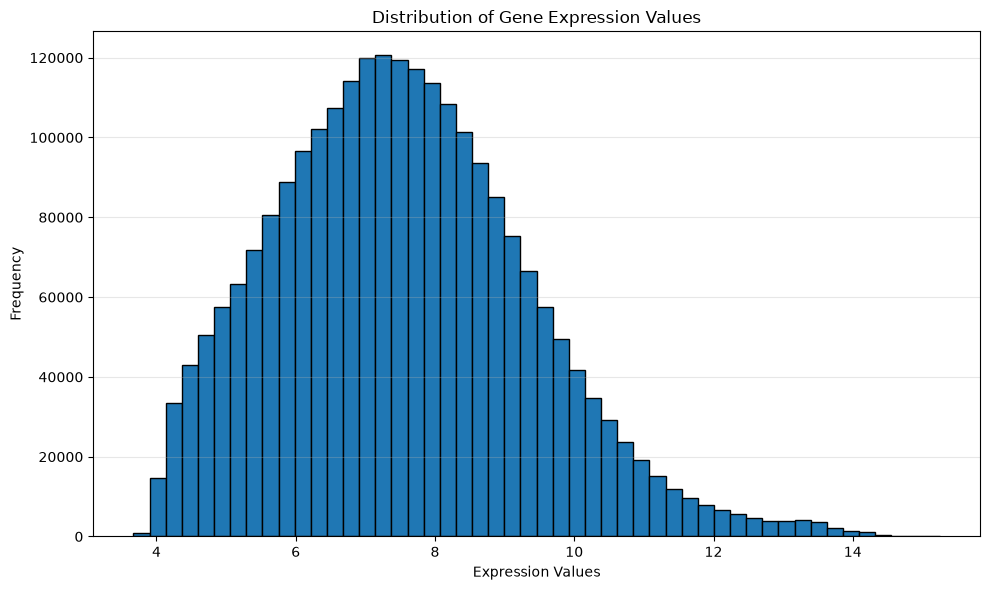

In [7]:
import matplotlib.pyplot as plt

# Flatten the expression matrix into a single array
expression_values = df.values.flatten()

# Create histogram
plt.figure(figsize=(10, 6))

plt.hist(expression_values, bins=50, edgecolor="black")

plt.title("Distribution of Gene Expression Values")
plt.xlabel("Expression Values")
plt.ylabel("Frequency")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Interpretation

The histogram illustrates the distribution of gene expression values across the GSE10072 dataset.

Most expression values are concentrated approximately between 5 and 10, with a peak around 7–8. The distribution also shows a right-sided tail, indicating that some probes have relatively higher expression values.

This visualization provides an overview of the overall expression-value distribution and helps identify its general pattern.

### 3.3: Overall Expression Distribution – Boxplot

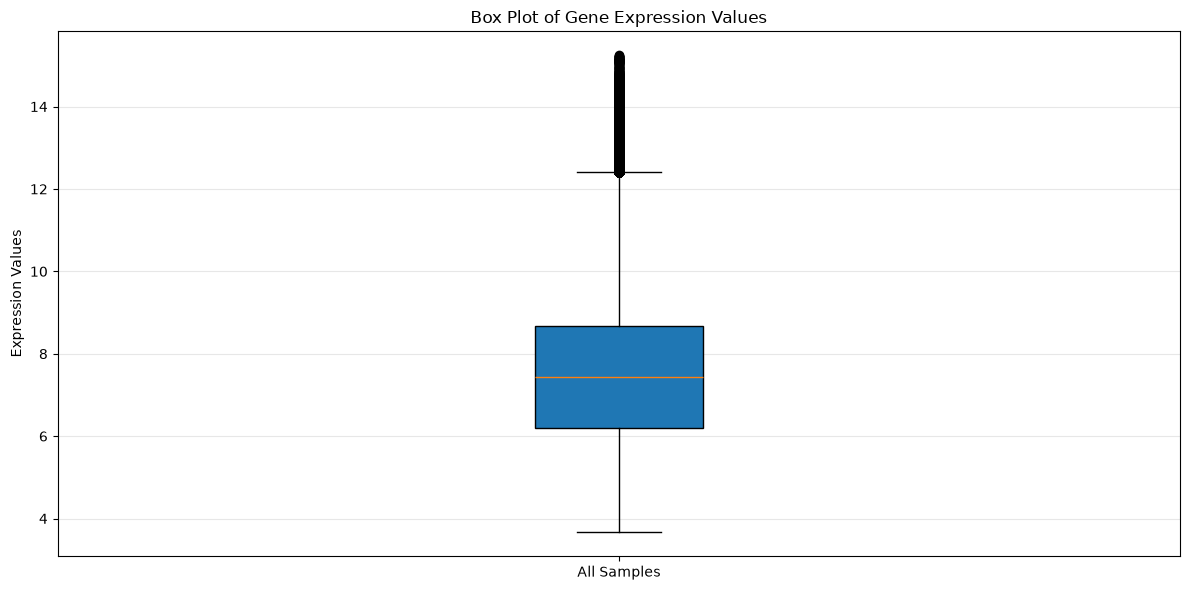

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.boxplot(
    df.values.flatten(),
    patch_artist=True,
    showfliers=True
)

plt.title("Box Plot of Gene Expression Values")
plt.ylabel("Expression Values")
plt.xticks([1], ["All Samples"])
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretation

The boxplot summarizes the overall distribution of gene expression values across the dataset.

The central line represents the median expression value, while the box represents the interquartile range (IQR), covering the middle 50% of observations.

The whiskers show the spread of values within the plotting rule, and individual points beyond the whiskers represent potential outliers.

The plot provides a compact overview of the central tendency, variability and spread of expression values.

### 3.4: Sample-wise Expression Distribution – Boxplots

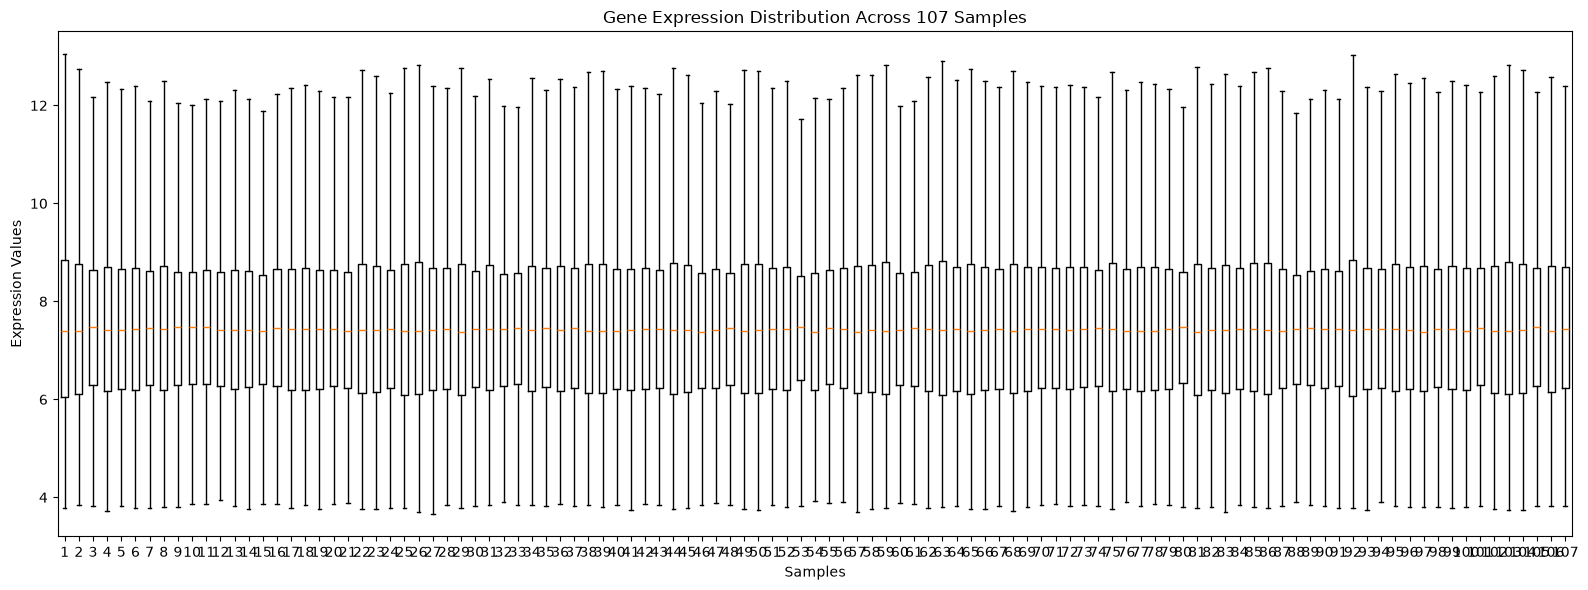

In [9]:
plt.figure(figsize=(16, 6))

plt.boxplot(
    df.values,
    showfliers=False
)

plt.title("Gene Expression Distribution Across 107 Samples")
plt.xlabel("Samples")
plt.ylabel("Expression Values")

plt.tight_layout()
plt.show()

### Interpretation

The sample-wise boxplot compares the distribution of gene expression values across all 107 samples in the GSE10072 dataset.

Each box represents one sample, showing its median, interquartile range and overall spread of expression values.

The boxplots show broadly similar expression distributions across samples, suggesting that the samples have comparable overall expression-value patterns.

This visualization is useful for identifying samples with noticeably different expression distributions that may require further investigation.

### 3.5	Expression Density Distribution

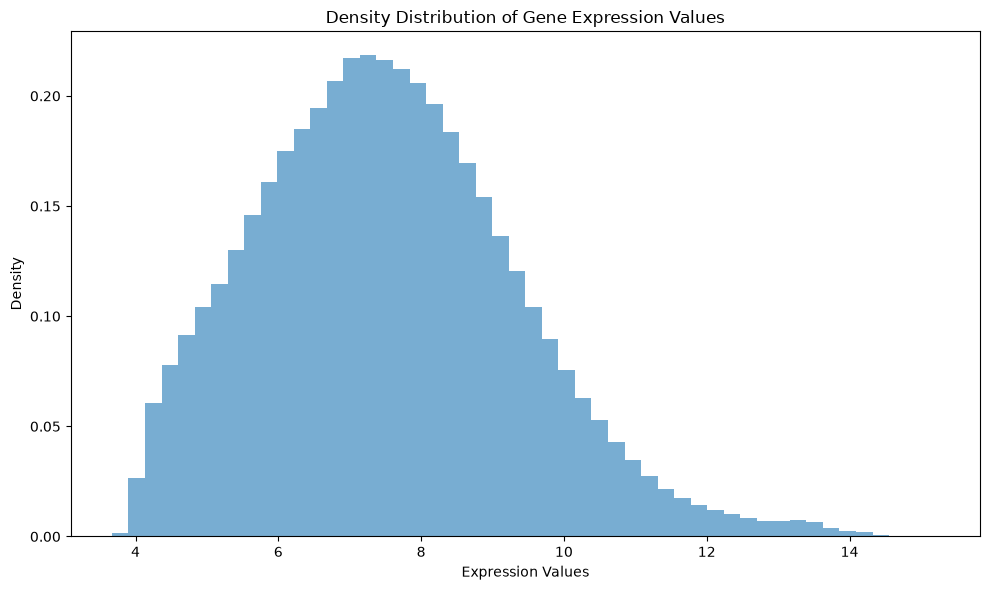

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.values.flatten(),
    bins=50,
    density=True,
    alpha=0.6
)

df.values.flatten()

plt.title("Density Distribution of Gene Expression Values")
plt.xlabel("Expression Values")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

#### Interpretation

The density-scaled histogram illustrates the distribution of gene expression values using probability density instead of absolute frequency.

The graph shows that most expression values are concentrated approximately between 6 and 9, with the highest density around 7–8.

The distribution exhibits positive (right) skewness, with a longer tail extending towards higher expression values.

Unlike a frequency histogram, density scaling normalizes the distribution, making it easier to examine the overall expression pattern independently of the total number of observations. The total area under the density histogram is approximately equal to 1.

This visualization provides an overview of the distribution, concentration and spread of gene expression values across the dataset.

### 3.6 Sample-wise Mean Expression

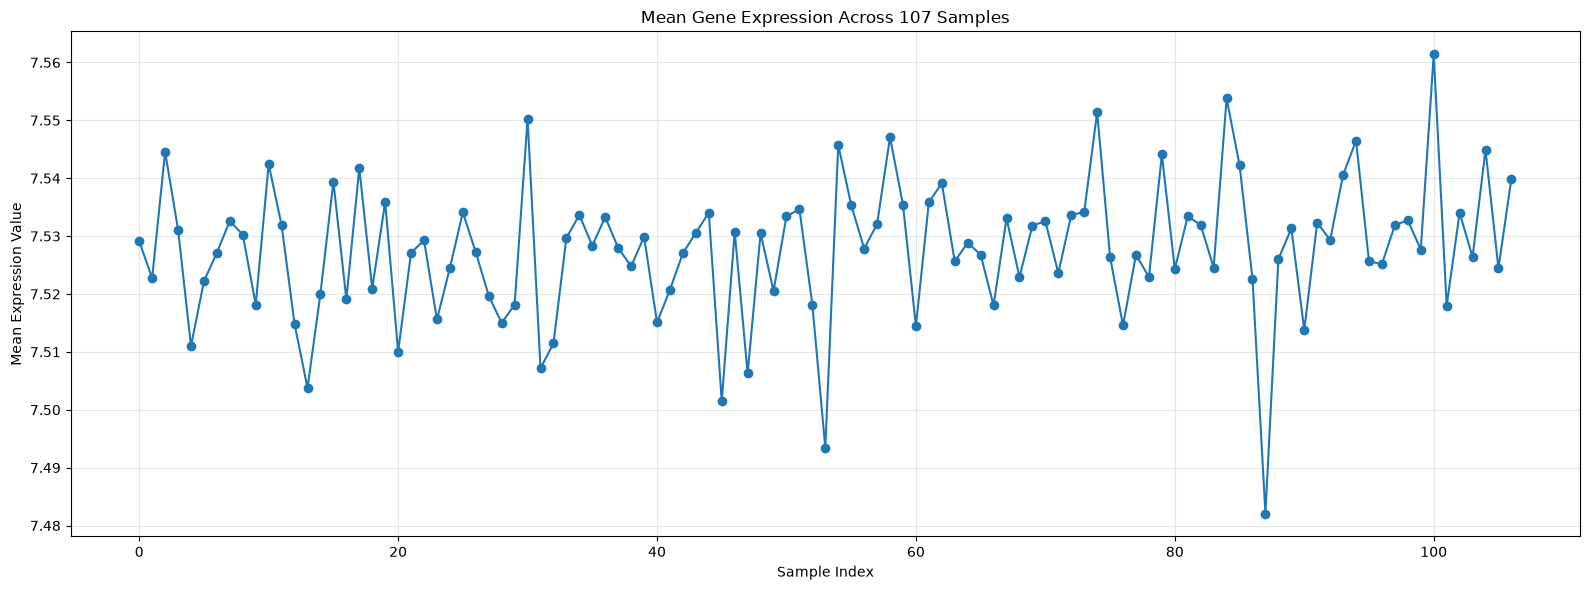

In [11]:
# Calculate mean expression for each sample
sample_means = df.mean(axis=0)

# Plot sample-wise mean expression
plt.figure(figsize=(16, 6))

plt.plot(sample_means.values, marker='o')

plt.title("Mean Gene Expression Across 107 Samples")
plt.xlabel("Sample Index")
plt.ylabel("Mean Expression Value")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
sample_means.head(10)

GSM254625    7.529112
GSM254626    7.522747
GSM254627    7.544572
GSM254628    7.531137
GSM254629    7.511000
GSM254630    7.522198
GSM254631    7.527134
GSM254632    7.532633
GSM254633    7.530241
GSM254634    7.518165
dtype: float64

#### Interpretation

The sample-wise mean expression plot represents the average expression value across all 22,283 probes for each of the 107 samples.

The mean expression values range from approximately 7.4821 to 7.5614, with an overall average of 7.5278 and a standard deviation of approximately 0.0120.

The graph shows relatively small fluctuations in average expression values across the samples, indicating consistency in their overall mean expression levels.

This suggests that the samples have broadly comparable average expression values. However, similar sample means do not necessarily indicate identical gene expression profiles, since individual probes may show substantial differences in expression between samples.

This visualization is useful for assessing sample-wise consistency in average expression values, but further analysis is required to investigate gene-level variation.

In [13]:
#Calculate the range of sample means
print("Minimum sample mean:", sample_means.min())
print("Maximum sample mean:", sample_means.max())
print("Overall average of sample means:", sample_means.mean())
print("Standard deviation of sample means:", sample_means.std())

Minimum sample mean: 7.482080238360364
Maximum sample mean: 7.561405257843962
Overall average of sample means: 7.52775932442687
Standard deviation of sample means: 0.012042245839606294


### 3.7 Tumor vs Non-Tumor Mean Expression Comparison

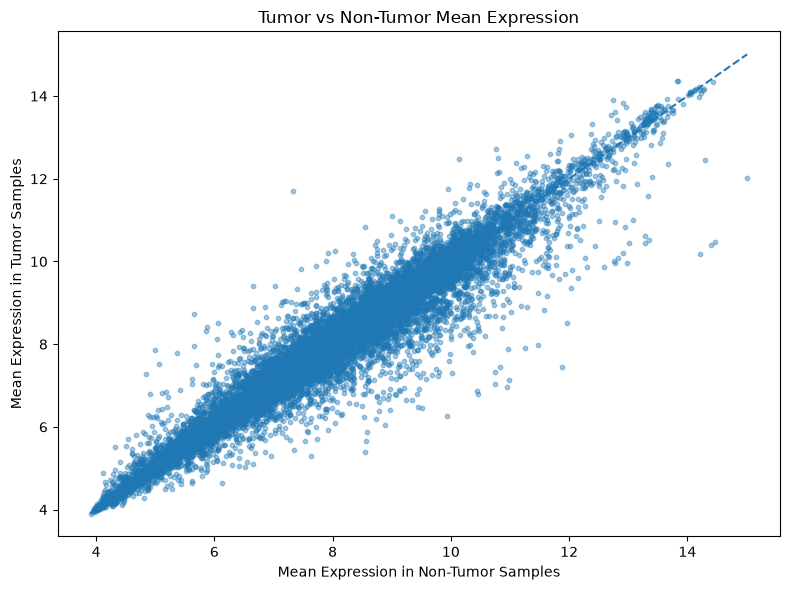

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    group_comparison["Non_Tumor_Mean"],
    group_comparison["Tumor_Mean"],
    alpha=0.4,
    s=10
)

# Add a diagonal reference line
min_val = min(
    group_comparison["Non_Tumor_Mean"].min(),
    group_comparison["Tumor_Mean"].min()
)

max_val = max(
    group_comparison["Non_Tumor_Mean"].max(),
    group_comparison["Tumor_Mean"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Mean Expression in Non-Tumor Samples")
plt.ylabel("Mean Expression in Tumor Samples")
plt.title("Tumor vs Non-Tumor Mean Expression")

plt.tight_layout()
plt.show()

#### Interpretation

The scatter plot compares the mean gene expression values of 22,283 probes between tumor and non-tumor lung tissue samples.

Each point represents an individual probe, with its tumor mean expression plotted against its non-tumor mean expression.

- **Points above the diagonal line:** Represent probes with higher mean expression in tumor samples.
- **Points below the diagonal line:** Represent probes with higher mean expression in non-tumor samples.
- **Points close to the diagonal line:** Indicate relatively similar mean expression values between the two groups.

The distribution of points around the diagonal provides an overview of differences in average gene expression between tumor and non-tumor samples.

This visualization helps identify probes showing potential differences in expression between the two groups and provides a basis for further investigation.

### 3.8 What the Visualizations Do Not Prove

Although the visualizations provide useful insights into the distribution, variation and overall patterns of gene expression values in the GSE10072 dataset, they have certain limitations.

**1. No confirmation of differential gene expression**

Histograms and boxplots illustrate the overall distribution of gene expression values but do not establish which individual genes are significantly differentially expressed between tumor and non-tumor samples.

**2. No proof of statistical significance**

Differences observed in the tumor vs non-tumor scatter plot represent differences in group mean expression values. These differences cannot be considered statistically significant without appropriate statistical testing and multiple-testing correction.

**3. No evidence of biological causation**

The observed expression patterns do not establish that a particular gene causes lung adenocarcinoma or directly contributes to disease development.

**4. No confirmation of outlier significance**

Values appearing beyond the boxplot whiskers are considered potential outliers based on the plotting rule. They are not automatically errors or biologically abnormal observations and require further investigation.

**5. No guarantee of complete data quality**

Similar sample-wise boxplots and small variations in sample mean expression suggest comparable overall expression distributions. However, these patterns do not guarantee the absence of technical variations, batch effects or other sources of experimental variability.

**6. No identification of biological pathways**

The visualizations do not independently identify enriched biological pathways, molecular mechanisms or functional relationships associated with lung adenocarcinoma.

**7. No complete assessment of individual gene behaviour**

Similar overall expression distributions and sample means do not imply that all genes have similar expression levels across samples. Individual probes may show substantial variations that are not visible in summary-level plots.

### Overall Limitation

The visualizations performed in this task are exploratory in nature. They help understand the distribution and variation of gene expression values and identify patterns that may require further investigation. However, additional statistical analyses, differential gene expression testing and functional enrichment analyses are necessary to establish stronger biological conclusions.

### 3.9 Overall Scientific Interpretation

The visualization and exploratory analysis of the GSE10072 dataset provided an overview of gene expression patterns across 107 lung tissue samples, comprising 58 tumor samples and 49 non-tumor samples.

The histogram and density-scaled histogram showed that most expression values were concentrated within a similar range, with a positively skewed distribution.

The overall boxplot summarized the central tendency and variability of expression values, while the sample-wise boxplots demonstrated broadly comparable expression distributions across the samples.

The sample-wise mean expression plot showed relatively small variations in average expression values, suggesting consistency in overall mean expression across the samples.

The tumor vs non-tumor comparison revealed differences in mean expression values among individual probes. Some probes showed higher average expression in tumor samples, whereas others showed higher average expression in non-tumor samples.

Overall, these visualizations demonstrate the usefulness of exploratory data analysis in identifying expression patterns, understanding sample variability and comparing gene expression between different tissue groups.

However, these observations are preliminary and require further statistical and functional analyses to investigate their biological significance.

### 3.10 Conclusion

The GSE10072 dataset was successfully explored using Python-based visualization techniques to understand gene expression patterns in lung adenocarcinoma and non-tumor lung tissue samples.

Six visualizations were generated to examine the distribution of expression values, sample-wise variability, average expression levels and differences between tumor and non-tumor groups.

The analysis revealed broadly comparable overall expression distributions across samples, along with variations in mean expression values between individual probes in the two tissue groups.

This task demonstrated how data visualization can help summarize complex biological datasets, identify patterns and support exploratory gene expression analysis.

Overall, the visualization and interpretation process strengthened the understanding of exploratory data analysis and its importance in bioinformatics research. Further statistical analysis is required to validate the observed differences and investigate their biological significance.
